In [1]:
import numpy as np

In [2]:
import pandas as pd

In [3]:
import yfinance as yf

In [4]:
import matplotlib.pyplot as plt

In [5]:
from scipy import optimize 

In [6]:
import mplfinance as mpf

In [7]:
plt.rcParams.update({
    'figure.figsize': (12,6),
    'figure.dpi': 100,
    'axes.grid': True,
    'grid.linestyle':'--',
    'grid.alpha': 0.3,
    'axes.labelsize':11,
    'axes.titlesize': 14,
    'legend.frameon': False, 
    'font.size': 10})

In [8]:
mc = mpf.make_marketcolors(up='green',
                           down ='red',
                           edge ='inherit',
                           wick ='inherit',
                           volume='inherit')

In [9]:
style = mpf.make_mpf_style(base_mpf_style ='yahoo',
                           marketcolors = mc,
                           gridstyle = '--',
                           gridcolor = 'grey',
                           facecolor ='white',
                           figcolor = 'white',
                           y_on_right = False,
                           rc = {'font.size':10})

# Data collection and cleaning 

In [10]:
Tickers = ('CRWD', '^GSPC', 'CIBR','PANW','FTNT','ZS')
Historical = pd.DataFrame()
for t in Tickers: 
    Historical[t] = yf.download(t, '2020-1-1', '2026-1-1')['Close']

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [11]:
Historical.dropna()

,CRWD,^GSPC,CIBR,PANW,FTNT,ZS
Date,,,,,,
2020-01-02,12.360000,3257.850098,29.211397,39.235001,21.936001,47.330002
2020-01-03,12.687500,3234.850098,29.288143,39.471668,22.242001,47.380001
2020-01-06,13.777500,3246.280029,29.647890,40.043331,22.400000,48.700001
2020-01-07,13.687500,3237.179932,29.671873,40.273335,22.378000,48.400002
2020-01-08,13.915000,3253.050049,29.844551,39.761665,22.733999,50.750000
...,...,...,...,...,...,...
2025-12-24,119.277496,6932.049805,72.661057,187.220001,81.180000,229.600006
2025-12-26,120.297501,6929.939941,72.950302,188.449997,81.559998,230.520004
2025-12-29,118.977501,6905.740234,72.361839,186.850006,80.820000,228.020004


In [12]:
Historical= Historical.rename(columns={'^GSPC': 'SP500'})

In [13]:
Historical

,CRWD,SP500,CIBR,PANW,FTNT,ZS
Date,,,,,,
2020-01-02,12.360000,3257.850098,29.211397,39.235001,21.936001,47.330002
2020-01-03,12.687500,3234.850098,29.288143,39.471668,22.242001,47.380001
2020-01-06,13.777500,3246.280029,29.647890,40.043331,22.400000,48.700001
2020-01-07,13.687500,3237.179932,29.671873,40.273335,22.378000,48.400002
2020-01-08,13.915000,3253.050049,29.844551,39.761665,22.733999,50.750000
...,...,...,...,...,...,...
2025-12-24,119.277496,6932.049805,72.661057,187.220001,81.180000,229.600006
2025-12-26,120.297501,6929.939941,72.950302,188.449997,81.559998,230.520004
2025-12-29,118.977501,6905.740234,72.361839,186.850006,80.820000,228.020004


In [14]:
tickers = ('CRWD', '^GSPC', 'CIBR','PANW','FTNT','ZS')
YTD = pd.DataFrame()
for t in tickers: 
    YTD[t] = yf.download (t, '2026-1-1', '2026-9-5')['Close']

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [15]:
YTD.dropna()

,CRWD,^GSPC,CIBR,PANW,FTNT,ZS
Date,,,,,,
2026-01-02,113.394997,6858.470215,70.496681,179.369995,77.879997,220.570007
2026-01-05,114.137497,6902.049805,71.344475,182.119995,77.940002,222.759995
2026-01-06,114.580002,6944.819824,72.002769,185.860001,78.440002,222.029999
2026-01-07,119.727501,6920.930176,73.259499,193.899994,80.019997,231.160004
2026-01-08,115.967499,6921.459961,72.192276,190.800003,78.050003,220.320007
...,...,...,...,...,...,...
2026-08-31,231.000000,7686.140137,100.150002,382.130005,170.929993,188.384995
2026-09-01,215.070007,7631.470215,96.199997,362.089996,161.850006,178.369995
2026-09-02,203.419998,7666.600098,93.540001,328.480011,154.539993,172.729996


In [16]:
YTD = YTD.rename(columns={'^GSPC':'SP500'})

In [17]:
YTD.dropna()

,CRWD,SP500,CIBR,PANW,FTNT,ZS
Date,,,,,,
2026-01-02,113.394997,6858.470215,70.496681,179.369995,77.879997,220.570007
2026-01-05,114.137497,6902.049805,71.344475,182.119995,77.940002,222.759995
2026-01-06,114.580002,6944.819824,72.002769,185.860001,78.440002,222.029999
2026-01-07,119.727501,6920.930176,73.259499,193.899994,80.019997,231.160004
2026-01-08,115.967499,6921.459961,72.192276,190.800003,78.050003,220.320007
...,...,...,...,...,...,...
2026-08-31,231.000000,7686.140137,100.150002,382.130005,170.929993,188.384995
2026-09-01,215.070007,7631.470215,96.199997,362.089996,161.850006,178.369995
2026-09-02,203.419998,7666.600098,93.540001,328.480011,154.539993,172.729996


# Calculating Historical Performance Metrics

In [18]:
SROR = Historical.pct_change()

In [19]:
CUM_Returns=(1+SROR).cumprod()-1

In [20]:
ANN_Returns=(1+SROR).resample('YE').prod()-1

In [21]:
ANN_EXPR = SROR.mean()*252

In [22]:
ANN_EXPV = SROR.std()*np.sqrt(252)

In [23]:
RFR = 0.0479

In [24]:
SHARPE = (ANN_EXPR - RFR)/ANN_EXPV

In [25]:
PEAK = Historical.cummax()
Drawdown = (Historical - PEAK)/PEAK 
Maximum = Drawdown.min()

In [26]:
date = Drawdown.idxmin()

In [27]:
date

CRWD    2023-01-06
SP500   2020-03-23
CIBR    2022-10-14
PANW    2020-03-18
FTNT    2023-11-07
ZS      2023-05-02
dtype: datetime64[s]

<Axes: xlabel='Date'>

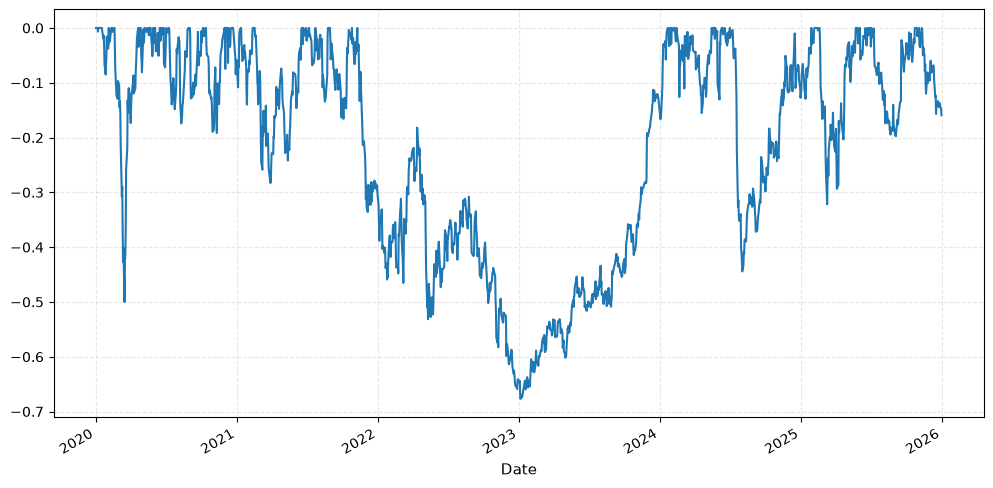

In [28]:
Drawdown['CRWD'].plot()

In [29]:
Correlation = SROR.corr()

In [30]:
ERP = ANN_EXPR['SP500']- RFR

In [31]:
Covariance = SROR.cov()*252

In [32]:
Variance = SROR.var()*252

In [33]:
Beta = Covariance['SP500']/Variance['SP500']

In [34]:
CAPM = RFR + Beta*ERP

# Visualization of Historical Performances

In [35]:
plt.rcParams.update({
    'figure.figsize': (12,6),
    'figure.dpi': 100,
    'axes.grid': True,
    'grid.linestyle':'--',
    'grid.alpha': 0.3,
    'axes.labelsize':11,
    'axes.titlesize': 14,
    'legend.frameon': False, 
    'font.size': 10})

In [36]:
Normalized = Historical[['CRWD','SP500','CIBR']]/Historical[['CRWD','SP500','CIBR']].iloc[0]*100

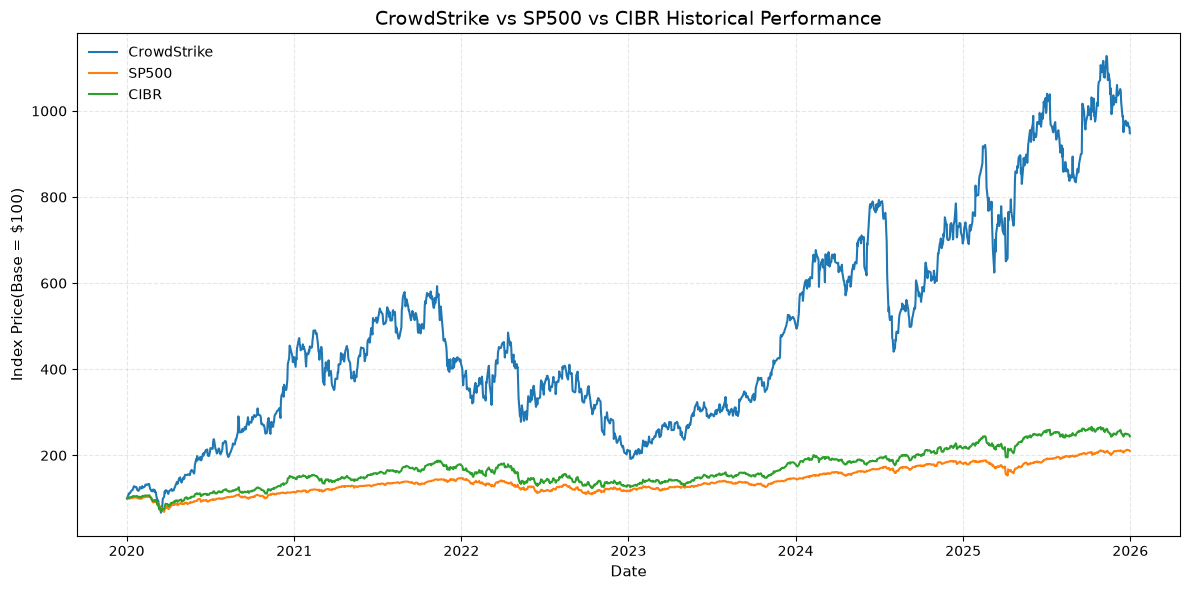

In [37]:
fig, ax = plt.subplots(figsize=(12,6))

ax.plot(Normalized.index, 
       Normalized['CRWD'],
       label ='CrowdStrike')
ax.plot(Normalized.index,
       Normalized['SP500'],
       label = 'SP500')
ax.plot(Normalized.index,
       Normalized['CIBR'],
       label = 'CIBR')

ax.set_title('CrowdStrike vs SP500 vs CIBR Historical Performance')
ax.set_xlabel('Date')
ax.set_ylabel('Index Price(Base = $100)')
ax.legend()

fig.tight_layout()

plt.show()

In [38]:
fig.savefig('CrowdStrike_SP500_historical.png', dpi=300, bbox_inches = 'tight')

In [39]:
Normalized1 = Historical[['CRWD','PANW','FTNT','ZS']]/Historical[['CRWD','PANW','FTNT','ZS']].iloc[0]*100

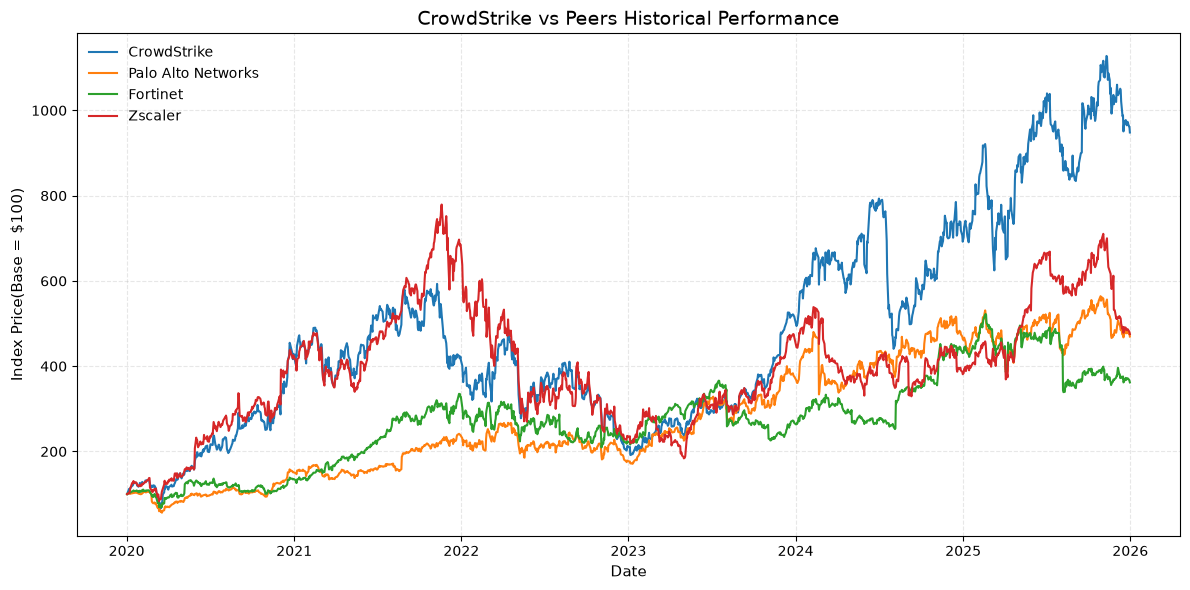

In [40]:
fig, ax = plt.subplots(figsize=(12,6))

ax.plot(Normalized1.index, 
       Normalized1['CRWD'],
       label ='CrowdStrike')
ax.plot(Normalized1.index,
       Normalized1['PANW'],
       label = 'Palo Alto Networks')
ax.plot(Normalized1.index,
       Normalized1['FTNT'],
       label = 'Fortinet')
ax.plot(Normalized1.index,
       Normalized1['ZS'],
       label = 'Zscaler')

ax.set_title('CrowdStrike vs Peers Historical Performance')
ax.set_xlabel('Date')
ax.set_ylabel('Index Price(Base = $100)')
ax.legend()

fig.tight_layout()

plt.show()

In [41]:
fig.savefig('Crowdstike_peers_historical.png', dpi = 300, bbox_inches='tight')

In [42]:
HIST_SUMMARY = pd.DataFrame({'Annualized Returns': ANN_EXPR, 
                             'Annualized Volatility': ANN_EXPV, 
                             'Beta': Beta, 
                             'Sharpe': SHARPE, 
                             'CAPM': CAPM,
                             'Maximum Drawdown': Maximum})

# Summary table for Historical Performance 

In [43]:
HIST_SUMMARY 

,Annualized Returns,Annualized Volatility,Beta,Sharpe,CAPM,Maximum Drawdown
CRWD,0.518355,0.533267,1.241488,0.882213,0.169888,-0.676922
SP500,0.146160,0.209271,1.000000,0.469534,0.146160,-0.339250
CIBR,0.183126,0.260203,0.999138,0.519695,0.146075,-0.338878
PANW,0.343578,0.408938,1.053836,0.723039,0.151450,-0.468020
FTNT,0.317287,0.448982,1.205207,0.599996,0.166323,-0.383159
ZS,0.416165,0.560094,1.207287,0.657505,0.166528,-0.764087


In [44]:
ANN_Returns 

,CRWD,SP500,CIBR,PANW,FTNT,ZS
Date,,,,,,
2020-12-31,3.284385,0.152929,0.484450,0.509664,0.354212,3.219522
2021-12-31,-0.033377,0.268927,0.196755,0.566617,1.419713,0.608983
2022-12-31,-0.485763,-0.194428,-0.264570,-0.248114,-0.319839,-0.651760
2023-12-31,1.424922,0.242305,0.397112,1.113229,0.197177,0.979982
2024-12-31,0.340122,0.233090,0.182106,0.234129,0.614215,-0.185728
2025-12-31,0.370002,0.163878,0.130635,0.012310,-0.159505,0.246716


# Calculating Year Till Date Performance

In [45]:
YTD_Return = (YTD.iloc[-1]/YTD.iloc[0]-1)

In [46]:
SROR1= YTD.pct_change()
YTD_VOL = SROR1.std()*np.sqrt(252)

In [47]:
PEAK1 = YTD.cummax()
Drawdown1 = (YTD - PEAK1)/ PEAK1
Maximum1 = Drawdown1.min()

In [48]:
SROR1 = YTD.pct_change()

In [49]:
EXPR1 = SROR1.mean()*252

In [50]:
Sharpe1 = (EXPR1 - RFR)/YTD_VOL

# Visualizations

In [51]:
Normalized2 = YTD[['CRWD','SP500','CIBR']]/YTD[['CRWD','SP500','CIBR']].iloc[0]*100

In [52]:
plt.rcParams.update({
    'figure.figsize': (12,6),
    'figure.dpi': 100,
    'axes.grid': True,
    'grid.linestyle':'--',
    'grid.alpha': 0.1,
    'axes.labelsize':11,
    'axes.titlesize': 14,
    'legend.frameon': False, 
    'font.size': 10})

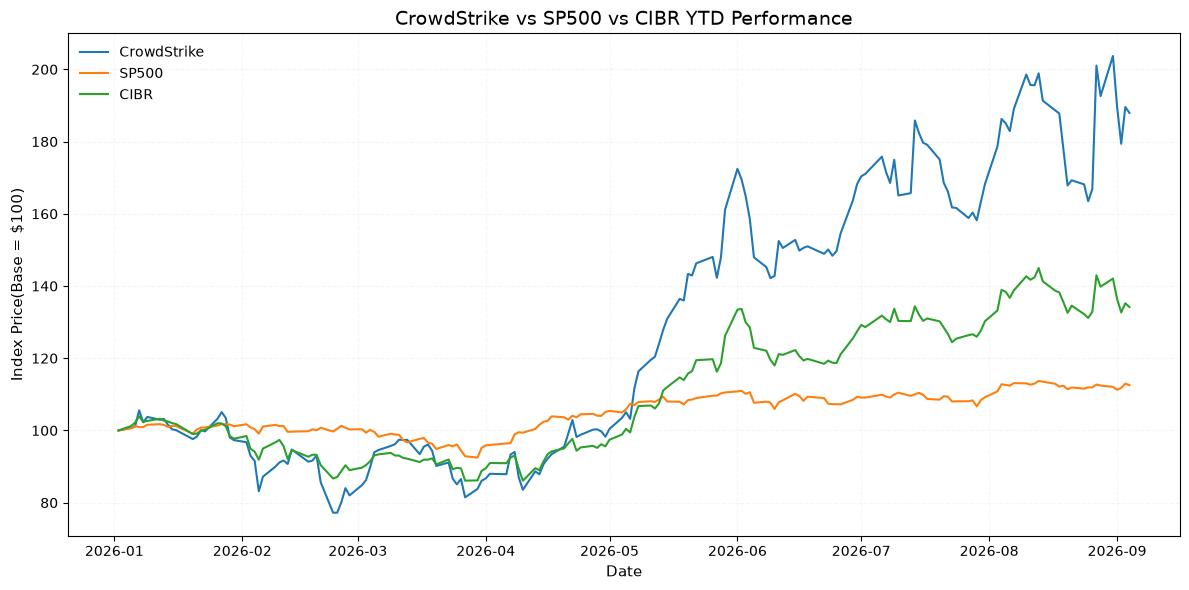

In [54]:
fig, ax = plt.subplots(figsize=(12,6))

ax.plot(Normalized2.index, 
       Normalized2['CRWD'],
       label ='CrowdStrike')
ax.plot(Normalized2.index,
       Normalized2['SP500'],
       label = 'SP500')
ax.plot(Normalized2.index,
       Normalized2['CIBR'],
       label = 'CIBR')
ax.set_title('CrowdStrike vs SP500 vs CIBR YTD Performance')
ax.set_xlabel('Date')
ax.set_ylabel('Index Price(Base = $100)')
ax.legend()
    
fig.tight_layout()

plt.show()

In [55]:
fig.savefig('CrowstrikevsYTD.png', dpi=300, bbox_inches='tight')

In [56]:
Normalized3 = YTD[['CRWD','PANW','FTNT','ZS']]/YTD[['CRWD','PANW','FTNT','ZS']].iloc[0]*100

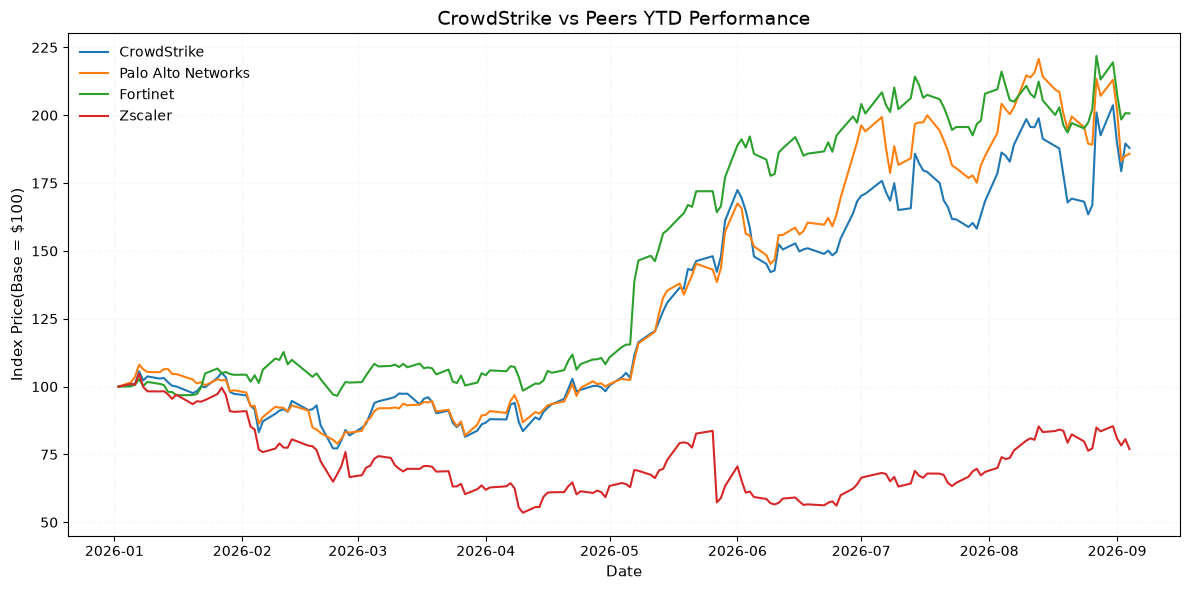

In [57]:
fig, ax = plt.subplots(figsize=(12,6))

ax.plot(Normalized3.index, 
       Normalized3['CRWD'],
       label ='CrowdStrike')
ax.plot(Normalized3.index,
       Normalized3['PANW'],
       label = 'Palo Alto Networks')
ax.plot(Normalized3.index,
       Normalized3['FTNT'],
       label = 'Fortinet')
ax.plot(Normalized3.index,
       Normalized3['ZS'],
       label = 'Zscaler')

ax.set_title('CrowdStrike vs Peers YTD Performance')
ax.set_xlabel('Date')
ax.set_ylabel('Index Price(Base = $100)')
ax.legend()

fig.tight_layout()

plt.show()

In [58]:
fig.savefig('CrowdStrike_vs_peers_YTD.png', dpi=300, bbox_inches='tight')

# YTD Summary Table

In [59]:
YTD_SUMMARY = pd.DataFrame({'Actual Return': YTD_Return,
                             'Actual Volatility': YTD_VOL,
                             'Maximum Drawdown': Maximum1,
                             'Sharpe Ratio': Sharpe1})

In [60]:
YTD_SUMMARY

,Actual Return,Actual Volatility,Maximum Drawdown,Sharpe Ratio
CRWD,0.879272,0.603212,-0.268652,1.777164
SP500,0.125411,0.134285,-0.090975,1.022415
CIBR,0.341765,0.320323,-0.171605,1.378559
PANW,0.857947,0.518277,-0.269366,1.948784
FTNT,1.006805,0.469699,-0.143361,2.339375
ZS,-0.230176,0.720429,-0.489315,-0.220236


# Technical Analysis 

In [61]:
TECH = yf.download('CRWD', '2025-1-1', '2026-09-05')

[*********************100%***********************]  1 of 1 completed


In [62]:
TECH1 = TECH[['Open','High','Low','Close','Volume']]

In [63]:
TECH1 = TECH1.apply(pd.to_numeric, errors='coerce')

TECH1 = TECH1.dropna().copy()

TECH1 = TECH1.astype(float)

In [64]:
print(type(TECH1['Open']))

<class 'pandas.DataFrame'>


In [65]:
TECH1 = TECH.xs('CRWD', axis=1, level='Ticker').copy()

In [66]:
TECH1 = TECH1[['Open', 'High', 'Low', 'Close', 'Volume']]

In [67]:
TECH1 = TECH1.apply(
    pd.to_numeric,
    errors='coerce'
)

In [68]:
TECH1 = TECH1.dropna().astype(float)

In [69]:
TECH1.index = pd.to_datetime(TECH1.index)
TECH1 = TECH1.sort_index()

In [70]:
print(type(TECH1['Open']))
print(TECH1.dtypes)

<class 'pandas.Series'>
Price
Open      float64
High      float64
Low       float64
Close     float64
Volume    float64
dtype: object


In [71]:
TECH1['50MA'] = TECH1['Close'].rolling(50).mean()

In [72]:
TECH1['100MA'] = TECH1['Close'].rolling(100).mean()

In [73]:
TECH1['200MA'] = TECH1['Close'].rolling(200).mean()

In [74]:
sma50 = mpf.make_addplot(TECH1['50MA'], color='blue',width=0.8)
sma100 = mpf.make_addplot(TECH1['100MA'], color='orange',width=1.5)
sma200 = mpf.make_addplot(TECH1['200MA'],color='purple', width=1.5)

findfont: Failed to find font weight semibold, now using 700.


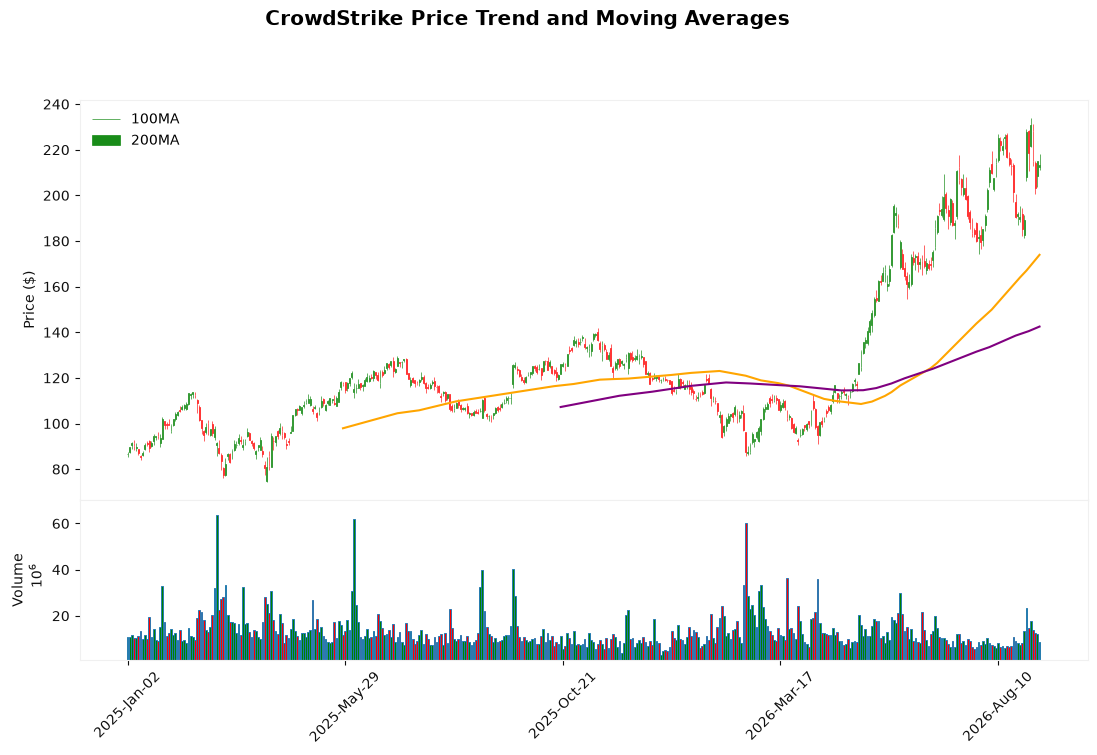

In [75]:

mc1 = mpf.make_marketcolors(
    up="#1a9850",
    down="#d73027",
    edge="inherit",
    wick="inherit",
    volume="inherit"
)


style1 = mpf.make_mpf_style(
    base_mpf_style="yahoo",
    marketcolors=mc1,
    gridstyle="--",
    gridcolor="#dddddd",
    facecolor="white",
    figcolor="white",
    y_on_right=False,
    rc={"font.size": 10}
)

fig, axes = mpf.plot(
    TECH1,
    type="candle",
    style=style,
    addplot=[sma100, sma200],
    volume=True,
    figsize=(14, 8),
    title="CrowdStrike Price Trend and Moving Averages",
    ylabel="Price ($)",
    ylabel_lower="Volume",
    returnfig=True
)

for ax in axes:
    ax.grid(False)


axes[0].legend(
    ["100MA", "200MA"],
    loc="upper left",
    frameon=False
)

plt.show()

In [76]:
fig.savefig('CrowdStrik_technicals.png', dpi =300, bbox_inches='tight')

# Monte Carlo Simulation 

In [77]:
Monte = yf.download ('CRWD', '2020-1-1','2026-9-5')['Close']

[*********************100%***********************]  1 of 1 completed


In [78]:
LROR= np.log(Monte).diff(1)

In [79]:
Mean = LROR.mean()

In [80]:
Vol= LROR.std()

In [81]:
Last_Price = Monte.iloc[-1].item()

In [82]:
Trading_days = 252

In [83]:
Simulation = 10000

In [84]:
Random_Returns = np.random.normal(Mean, Vol,(Trading_days, Simulation))

In [85]:
Simulated_Prices = Last_Price * np.exp(np.cumsum(Random_Returns, axis =0))

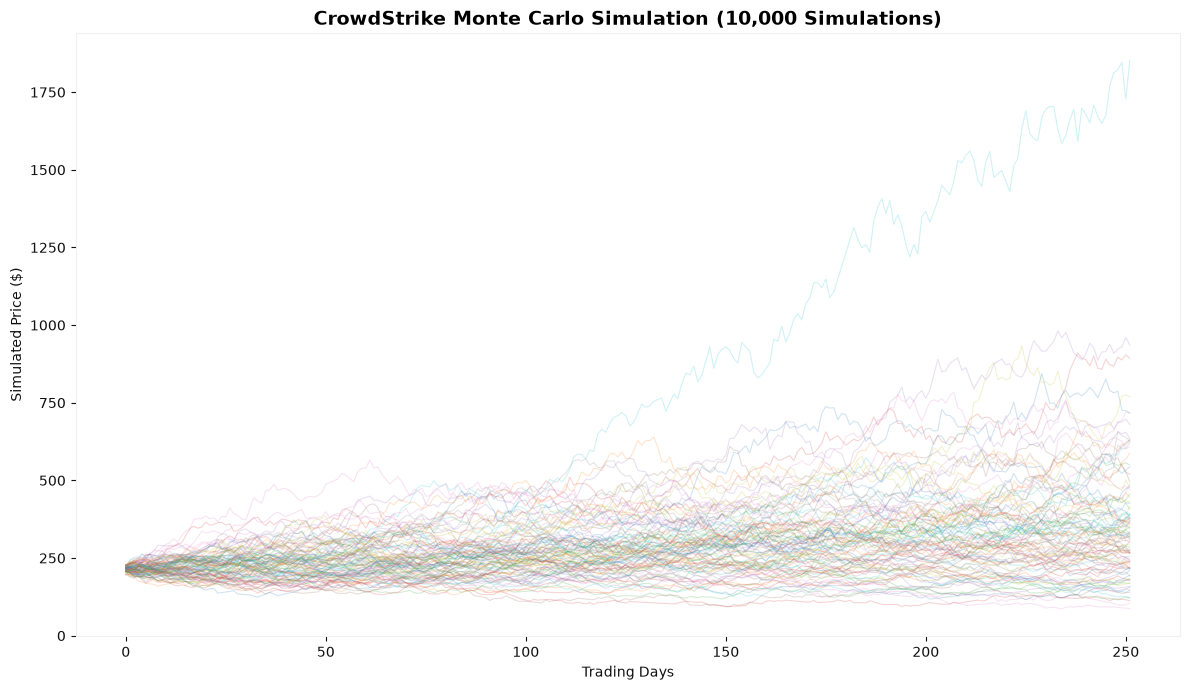

In [86]:
fig, ax = plt.subplots(figsize=(12, 7))

ax.plot(
    Simulated_Prices[:, :100],
    alpha=0.20,
    linewidth=0.8
)

ax.set_title(
    'CrowdStrike Monte Carlo Simulation (10,000 Simulations)',
    fontsize=14,
    fontweight='bold'
)

ax.set_xlabel('Trading Days')
ax.set_ylabel('Simulated Price ($)')

ax.grid(False)

fig.tight_layout()

plt.show()

In [87]:
fig.savefig('CrowdStrike_Monte.png', dpi=300, bbox_inches='tight')

In [88]:
Final_Price = Simulated_Prices[-1]

In [89]:
Mean_Final_Price = np.mean(Final_Price)
Median_Final_Price = np.median(Final_Price)
Percentile_5 = np.percentile(Final_Price, 5)
Percentile_25 = np.percentile(Final_Price, 25)
Percentile_75 = np.percentile(Final_Price, 75)
Percentile_95 = np.percentile(Final_Price, 95)

In [90]:
Probability_profit = np.mean(Final_Price>Last_Price)

In [91]:
Probability_loss = np.mean(Final_Price<Last_Price)

In [92]:
MONTE_SUMMARY = pd.DataFrame({'Current Price': Last_Price,
                        'Mean Simulated Price': Mean_Final_Price,
                        'Median Simulated Price': Median_Final_Price,
                        '5th Percentile': Percentile_5,
                        '25th Percentile': Percentile_25,
                        '75th Percentile': Percentile_75,
                        '95th Percentile': Percentile_95, 
                        'Probability of Profit': Probability_profit,
                        'Probability of loss': Probability_loss}, index =[0])

In [93]:
MONTE_SUMMARY

,Current Price,Mean Simulated Price,Median Simulated Price,5th Percentile,25th Percentile,75th Percentile,95th Percentile,Probability of Profit,Probability of loss
0,213.100006,376.309004,325.090799,134.957901,225.418384,467.935845,794.943135,0.7822,0.2178
